In [5]:
import pandas as pd
import numpy as np

In [6]:
from ucimlrepo import fetch_ucirepo 
# fetch dataset 
online_retail = fetch_ucirepo(id=352) 
# data (as pandas dataframes) 
df = online_retail.data.original.copy() 


In [7]:
df.shape

(541909, 8)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


In [9]:
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


In [10]:
missing_summary = pd.DataFrame({
    "jumlah_missing": df.isna().sum(),
    "persentase_missing": df.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by="jumlah_missing",
    ascending=False
)

missing_summary

,jumlah_missing,persentase_missing
CustomerID,135080,24.926694
Description,1454,0.268311
InvoiceNo,0,0.000000
StockCode,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
Country,0,0.000000


In [11]:
df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [12]:
cancelled_mask = (
    df["InvoiceNo"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.startswith("C")
)

jumlah_baris_cancelled = cancelled_mask.sum()

jumlah_invoice_cancelled = (
    df.loc[cancelled_mask, "InvoiceNo"]
    .nunique()
)

print("Jumlah baris transaksi pembatalan :", jumlah_baris_cancelled)
print("Jumlah invoice pembatalan         :", jumlah_invoice_cancelled)

Jumlah baris transaksi pembatalan : 9288
Jumlah invoice pembatalan         : 3836


In [13]:
quantity_nonpositif_mask = df["Quantity"] <= 0

jumlah_quantity_nonpositif = quantity_nonpositif_mask.sum()
jumlah_quantity_negatif = (df["Quantity"] < 0).sum()
jumlah_quantity_nol = (df["Quantity"] == 0).sum()

print(
    "Jumlah baris dengan Quantity < 0  :",
    jumlah_quantity_negatif
)

print(
    "Jumlah baris dengan Quantity = 0  :",
    jumlah_quantity_nol
)

print(
    "Jumlah baris dengan Quantity <= 0 :",
    jumlah_quantity_nonpositif
)

Jumlah baris dengan Quantity < 0  : 10624
Jumlah baris dengan Quantity = 0  : 0
Jumlah baris dengan Quantity <= 0 : 10624


In [14]:
display(
    df.loc[
        quantity_nonpositif_mask,
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "UnitPrice"
        ]
    ].head(10)
)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
141,C536379,D,Discount,-1,27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25


In [15]:
cancelled_mask = (
    df["InvoiceNo"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.startswith("C")
)

quantity_negatif_mask = df["Quantity"] < 0

jumlah_cancelled_dan_negatif = (
    cancelled_mask
    & quantity_negatif_mask
).sum()

jumlah_cancelled_quantity_positif = (
    cancelled_mask
    & ~quantity_negatif_mask
).sum()

jumlah_non_cancelled_quantity_negatif = (
    ~cancelled_mask
    & quantity_negatif_mask
).sum()

jumlah_non_cancelled_quantity_positif = (
    ~cancelled_mask
    & ~quantity_negatif_mask
).sum()

print(
    "Invoice C dan Quantity negatif       :",
    jumlah_cancelled_dan_negatif
)

print(
    "Invoice C tetapi Quantity positif    :",
    jumlah_cancelled_quantity_positif
)

print(
    "Bukan Invoice C, Quantity negatif    :",
    jumlah_non_cancelled_quantity_negatif
)

print(
    "Bukan Invoice C, Quantity positif    :",
    jumlah_non_cancelled_quantity_positif
)

print(
    "\nTotal seluruh baris                   :",
    (
        jumlah_cancelled_dan_negatif
        + jumlah_cancelled_quantity_positif
        + jumlah_non_cancelled_quantity_negatif
        + jumlah_non_cancelled_quantity_positif
    )
)

Invoice C dan Quantity negatif       : 9288
Invoice C tetapi Quantity positif    : 0
Bukan Invoice C, Quantity negatif    : 1336
Bukan Invoice C, Quantity positif    : 531285

Total seluruh baris                   : 541909


In [16]:
non_cancelled_negative = df.loc[
    (~cancelled_mask) & quantity_negatif_mask,
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice"
    ]
].copy()

display(non_cancelled_negative.head(20))

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
2406,536589,21777,NaN,-10,0.0
4347,536764,84952C,NaN,-38,0.0
7188,536996,22712,NaN,-20,0.0
7189,536997,22028,NaN,-20,0.0
7190,536998,85067,NaN,-6,0.0
7192,537000,21414,NaN,-22,0.0
7193,537001,21653,NaN,-6,0.0
7195,537003,85126,NaN,-2,0.0
7196,537004,21814,NaN,-30,0.0
7197,537005,21692,NaN,-70,0.0


In [17]:
description_kosong_mask = (
    df["Description"].isna()
    | df["Description"].astype(str).str.strip().eq("")
)

quantity_nonpositif_mask = df["Quantity"] <= 0

cancelled_mask = (
    df["InvoiceNo"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.startswith("C")
)

jumlah_description_kosong = (
    description_kosong_mask.sum()
)

jumlah_description_kosong_quantity_nonpositif = (
    description_kosong_mask
    & quantity_nonpositif_mask
).sum()

jumlah_description_kosong_quantity_positif = (
    description_kosong_mask
    & (df["Quantity"] > 0)
).sum()

jumlah_description_terisi_quantity_nonpositif = (
    ~description_kosong_mask
    & quantity_nonpositif_mask
).sum()

print(
    "Jumlah Description kosong                    :",
    jumlah_description_kosong
)

print(
    "Description kosong dan Quantity <= 0          :",
    jumlah_description_kosong_quantity_nonpositif
)

print(
    "Description kosong tetapi Quantity > 0        :",
    jumlah_description_kosong_quantity_positif
)

print(
    "Description terisi tetapi Quantity <= 0       :",
    jumlah_description_terisi_quantity_nonpositif
)

Jumlah Description kosong                    : 1454
Description kosong dan Quantity <= 0          : 862
Description kosong tetapi Quantity > 0        : 592
Description terisi tetapi Quantity <= 0       : 9762


In [18]:
jumlah_non_c_negatif_description_kosong = (
    ~cancelled_mask
    & quantity_nonpositif_mask
    & description_kosong_mask
).sum()

jumlah_non_c_negatif_description_terisi = (
    ~cancelled_mask
    & quantity_nonpositif_mask
    & ~description_kosong_mask
).sum()

print(
    "Non-C, Quantity negatif, Description kosong :",
    jumlah_non_c_negatif_description_kosong
)

print(
    "Non-C, Quantity negatif, Description terisi :",
    jumlah_non_c_negatif_description_terisi
)

Non-C, Quantity negatif, Description kosong : 862
Non-C, Quantity negatif, Description terisi : 474


In [19]:
description_kosong_positif = df.loc[
    description_kosong_mask
    & (df["Quantity"] > 0),
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice"
    ]
].copy()

display(description_kosong_positif.head(20))

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
622,536414,22139,NaN,56,0.0
1970,536545,21134,NaN,1,0.0
1971,536546,22145,NaN,1,0.0
1972,536547,37509,NaN,1,0.0
1987,536549,85226A,NaN,1,0.0
1988,536550,85044,NaN,1,0.0
2024,536552,20950,NaN,1,0.0
2025,536553,37461,NaN,3,0.0
2026,536554,84670,NaN,23,0.0
4348,536765,84952C,NaN,19,0.0


In [20]:
invoice_kosong_mask = df["InvoiceNo"].isna()

description_kosong_mask = (
    df["Description"].isna()
    | df["Description"]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
)

cancelled_mask = (
    df["InvoiceNo"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.startswith("C", na=False)
)

quantity_nonpositif_mask = (
    df["Quantity"] <= 0
)

hapus_mask = (
    invoice_kosong_mask
    | description_kosong_mask
    | cancelled_mask
    | quantity_nonpositif_mask
)

print(
    "InvoiceNo kosong                  :",
    invoice_kosong_mask.sum()
)

print(
    "Description kosong                :",
    description_kosong_mask.sum()
)

print(
    "Invoice pembatalan                :",
    cancelled_mask.sum()
)

print(
    "Quantity <= 0                     :",
    quantity_nonpositif_mask.sum()
)

print(
    "Total baris unik yang akan dihapus:",
    hapus_mask.sum()
)

print(
    "Total baris yang akan dipertahankan:",
    (~hapus_mask).sum()
)

InvoiceNo kosong                  : 0
Description kosong                : 1454
Invoice pembatalan                : 9288
Quantity <= 0                     : 10624
Total baris unik yang akan dihapus: 11216
Total baris yang akan dipertahankan: 530693


In [21]:
jumlah_baris_sebelum = len(df)

jumlah_invoice_sebelum = (
    df["InvoiceNo"]
    .nunique(dropna=True)
)

jumlah_baris_setelah_filter = (
    (~hapus_mask).sum()
)

jumlah_invoice_setelah_filter = (
    df.loc[
        ~hapus_mask,
        "InvoiceNo"
    ]
    .nunique(dropna=True)
)

print(
    "Jumlah baris sebelum pembersihan :",
    jumlah_baris_sebelum
)

print(
    "Jumlah baris setelah pembersihan :",
    jumlah_baris_setelah_filter
)

print(
    "Jumlah invoice sebelum pembersihan:",
    jumlah_invoice_sebelum
)

print(
    "Jumlah invoice setelah pembersihan:",
    jumlah_invoice_setelah_filter
)

Jumlah baris sebelum pembersihan : 541909
Jumlah baris setelah pembersihan : 530693
Jumlah invoice sebelum pembersihan: 25900
Jumlah invoice setelah pembersihan: 20136


In [22]:
df_clean = df.loc[~hapus_mask].copy()

df_clean["InvoiceNo"] = (
    df_clean["InvoiceNo"]
    .astype("string")
    .str.strip()
)

df_clean["StockCode"] = (
    df_clean["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_clean["Description"] = (
    df_clean["Description"]
    .astype("string")
    .str.strip()
    .str.replace(
        r"\s+",
        " ",
        regex=True
    )
    .str.upper()
)

df_clean = df_clean.reset_index(drop=True)

print("Ukuran df_clean:", df_clean.shape)

display(df_clean.head())

Ukuran df_clean: (530693, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [23]:
validasi_pembersihan = pd.DataFrame({
    "Pemeriksaan": [
        "InvoiceNo kosong",
        "Description kosong",
        "Description berupa string kosong",
        "Invoice pembatalan",
        "Quantity <= 0"
    ],
    "Jumlah": [
        df_clean["InvoiceNo"].isna().sum(),

        df_clean["Description"].isna().sum(),

        (
            df_clean["Description"]
            .str.strip()
            .eq("")
            .sum()
        ),

        (
            df_clean["InvoiceNo"]
            .str.upper()
            .str.startswith("C", na=False)
            .sum()
        ),

        (
            df_clean["Quantity"] <= 0
        ).sum()
    ]
})

display(validasi_pembersihan)

print(
    "Jumlah baris df_clean  :",
    len(df_clean)
)

print(
    "Jumlah invoice unik    :",
    df_clean["InvoiceNo"].nunique()
)

,Pemeriksaan,Jumlah
0,InvoiceNo kosong,0
1,Description kosong,0
2,Description berupa string kosong,0
3,Invoice pembatalan,0
4,Quantity <= 0,0


Jumlah baris df_clean  : 530693
Jumlah invoice unik    : 20136


In [24]:
duplikat_invoice_stockcode = (
    df_clean.duplicated(
        subset=[
            "InvoiceNo",
            "StockCode"
        ],
        keep=False
    )
)

duplikat_invoice_description = (
    df_clean.duplicated(
        subset=[
            "InvoiceNo",
            "Description"
        ],
        keep=False
    )
)

jumlah_baris_duplikat_stockcode = (
    duplikat_invoice_stockcode.sum()
)

jumlah_baris_duplikat_description = (
    duplikat_invoice_description.sum()
)

jumlah_pasangan_unik_stockcode_berulang = (
    df_clean.loc[
        duplikat_invoice_stockcode,
        [
            "InvoiceNo",
            "StockCode"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

jumlah_pasangan_unik_description_berulang = (
    df_clean.loc[
        duplikat_invoice_description,
        [
            "InvoiceNo",
            "Description"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

print(
    "Baris dalam pasangan InvoiceNo-StockCode berulang :",
    jumlah_baris_duplikat_stockcode
)

print(
    "Pasangan InvoiceNo-StockCode yang berulang         :",
    jumlah_pasangan_unik_stockcode_berulang
)

print(
    "Baris dalam pasangan InvoiceNo-Description berulang:",
    jumlah_baris_duplikat_description
)

print(
    "Pasangan InvoiceNo-Description yang berulang       :",
    jumlah_pasangan_unik_description_berulang
)

Baris dalam pasangan InvoiceNo-StockCode berulang : 20138
Pasangan InvoiceNo-StockCode yang berulang         : 9601
Baris dalam pasangan InvoiceNo-Description berulang: 20751
Pasangan InvoiceNo-Description yang berulang       : 9894


In [25]:
transactions = (
    df_clean
    .groupby("InvoiceNo")["Description"]
    .apply(lambda products: sorted(set(products)))
    .tolist()
)

print("Jumlah transaksi:", len(transactions))

print("\nContoh 5 transaksi pertama:")
for i, transaction in enumerate(transactions[:5], start=1):
    print(f"\nTransaksi {i}")
    print(transaction)

Jumlah transaksi: 20136

Contoh 5 transaksi pertama:

Transaksi 1
['CREAM CUPID HEARTS COAT HANGER', 'GLASS STAR FROSTED T-LIGHT HOLDER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.', 'SET 7 BABUSHKA NESTING BOXES', 'WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN']

Transaksi 2
['HAND WARMER RED POLKA DOT', 'HAND WARMER UNION JACK']

Transaksi 3
['ASSORTED COLOUR BIRD ORNAMENT', 'BOX OF 6 ASSORTED COLOUR TEASPOONS', 'BOX OF VINTAGE ALPHABET BLOCKS', 'BOX OF VINTAGE JIGSAW BLOCKS', 'DOORMAT NEW ENGLAND', 'FELTCRAFT PRINCESS CHARLOTTE DOLL', 'HOME BUILDING BLOCK WORD', 'IVORY KNITTED MUG COSY', 'LOVE BUILDING BLOCK WORD', "POPPY'S PLAYHOUSE BEDROOM", "POPPY'S PLAYHOUSE KITCHEN", 'RECIPE BOX WITH METAL HEART']

Transaksi 4
['BLUE COAT RACK PARIS FASHION', 'JAM MAKING SET WITH JARS', 'RED COAT RACK PARIS FASHION', 'YELLOW COAT RACK PARIS FASHION']

Transaksi 5
['BATH BUILDING BLOCK WORD']


In [26]:
transaction_sizes = pd.Series(
    [len(transaction) for transaction in transactions],
    name="Jumlah Produk Unik"
)

display(transaction_sizes.describe())

print(
    "Jumlah transaksi dengan satu produk:",
    (transaction_sizes == 1).sum()
)

print(
    "Jumlah transaksi dengan lebih dari satu produk:",
    (transaction_sizes > 1).sum()
)

count    20136.000000
mean        25.816250
std         46.789132
min          1.000000
25%          6.000000
50%         15.000000
75%         29.000000
max       1108.000000
Name: Jumlah Produk Unik, dtype: float64

Jumlah transaksi dengan satu produk: 1798
Jumlah transaksi dengan lebih dari satu produk: 18338


In [ ]:
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()

basket_array = te.fit(transactions).transform(
    transactions,
    sparse=True
)

basket = pd.DataFrame.sparse.from_spmatrix(
    basket_array,
    columns=te.columns_
).astype(bool)

basket.shape

(20136, 4052)

In [28]:
from mlxtend.frequent_patterns import fpgrowth

MIN_SUPPORT = 0.01

frequent_itemsets = fpgrowth(
    basket,
    min_support=MIN_SUPPORT,
    use_colnames=True
)

frequent_itemsets["jumlah_item"] = (
    frequent_itemsets["itemsets"].apply(len)
)

frequent_itemsets = (
    frequent_itemsets
    .sort_values(
        by=["support", "jumlah_item"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

frequent_itemsets.head(20)

,support,itemsets,jumlah_item
0,0.112237,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
1,0.103894,frozenset({JUMBO BAG RED RETROSPOT}),1
2,0.098778,frozenset({REGENCY CAKESTAND 3 TIER}),1
3,0.083731,frozenset({PARTY BUNTING}),1
4,0.077672,frozenset({LUNCH BAG RED RETROSPOT}),1
5,0.072259,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
6,0.068782,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
7,0.065554,frozenset({PACK OF 72 RETROSPOT CAKE CASES}),1
8,0.063816,frozenset({LUNCH BAG SUKI DESIGN}),1
9,0.063220,frozenset({LUNCH BAG BLACK SKULL.}),1


In [29]:
frequent_itemsets.shape

(1870, 3)

In [30]:
MIN_CONFIDENCE = 0.5

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=MIN_CONFIDENCE
)

rules.shape

(871, 10)

In [31]:
rules["antecedents_text"] = rules["antecedents"].apply(
    lambda items: ", ".join(sorted(items))
)

rules["consequents_text"] = rules["consequents"].apply(
    lambda items: ", ".join(sorted(items))
)

rules = rules.sort_values(
    by=["lift", "confidence", "support"],
    ascending=False
).reset_index(drop=True)

rules[
    [
        "antecedents_text",
        "consequents_text",
        "support",
        "confidence",
        "lift"
    ]
].head(20)

,antecedents_text,consequents_text,support,confidence,lift
0,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010081,0.944186,80.219959
1,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.010081,0.856540,80.219959
2,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.010081,0.845833,79.961033
3,"HERB MARKER PARSLEY, HERB MARKER THYME",HERB MARKER ROSEMARY,0.010081,0.953052,79.961033
4,HERB MARKER THYME,HERB MARKER ROSEMARY,0.010975,0.932489,78.235865
5,HERB MARKER ROSEMARY,HERB MARKER THYME,0.010975,0.920833,78.235865
6,"HERB MARKER ROSEMARY, HERB MARKER THYME",HERB MARKER PARSLEY,0.010081,0.918552,77.714134
7,HERB MARKER PARSLEY,"HERB MARKER ROSEMARY, HERB MARKER THYME",0.010081,0.852941,77.714134
8,HERB MARKER THYME,HERB MARKER PARSLEY,0.010578,0.898734,76.037443
9,HERB MARKER PARSLEY,HERB MARKER THYME,0.010578,0.894958,76.037443


In [32]:
top_3_rules = rules[
    [
        "antecedents_text",
        "consequents_text",
        "support",
        "confidence",
        "lift"
    ]
].head(3).copy()

top_3_rules

,antecedents_text,consequents_text,support,confidence,lift
0,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010081,0.944186,80.219959
1,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.010081,0.856540,80.219959
2,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.010081,0.845833,79.961033


In [33]:
top_3_rules["jumlah_transaksi"] = (
    top_3_rules["support"] * len(basket)
).round().astype(int)

top_3_rules[
    [
        "antecedents_text",
        "consequents_text",
        "jumlah_transaksi",
        "support",
        "confidence",
        "lift"
    ]
]

,antecedents_text,consequents_text,jumlah_transaksi,support,confidence,lift
0,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,203,0.010081,0.944186,80.219959
1,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",203,0.010081,0.856540,80.219959
2,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",203,0.010081,0.845833,79.961033


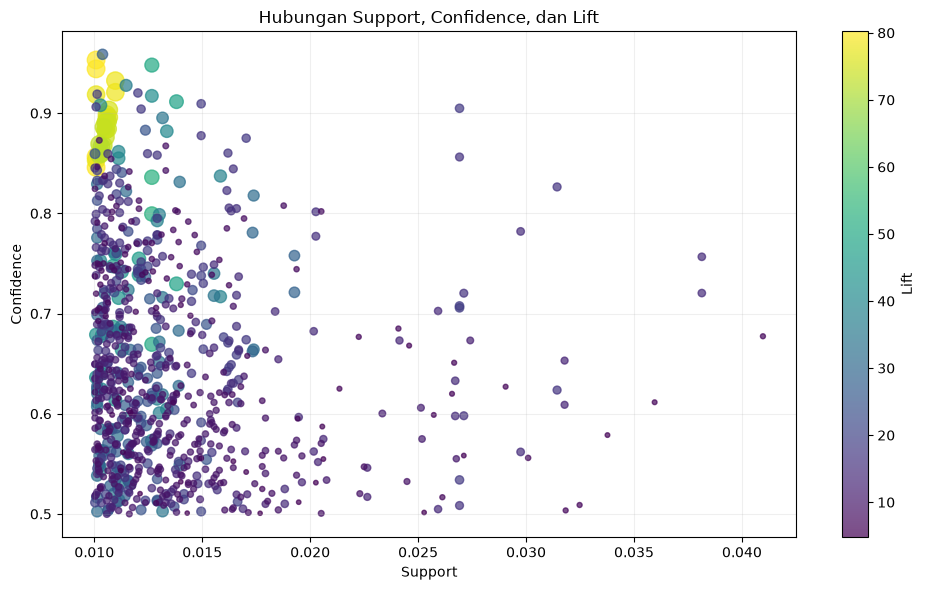

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rules["support"],
    rules["confidence"],
    c=rules["lift"],
    s=rules["lift"] * 2,
    cmap="viridis",
    alpha=0.7
)

plt.colorbar(scatter, label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Hubungan Support, Confidence, dan Lift")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "association_rules_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

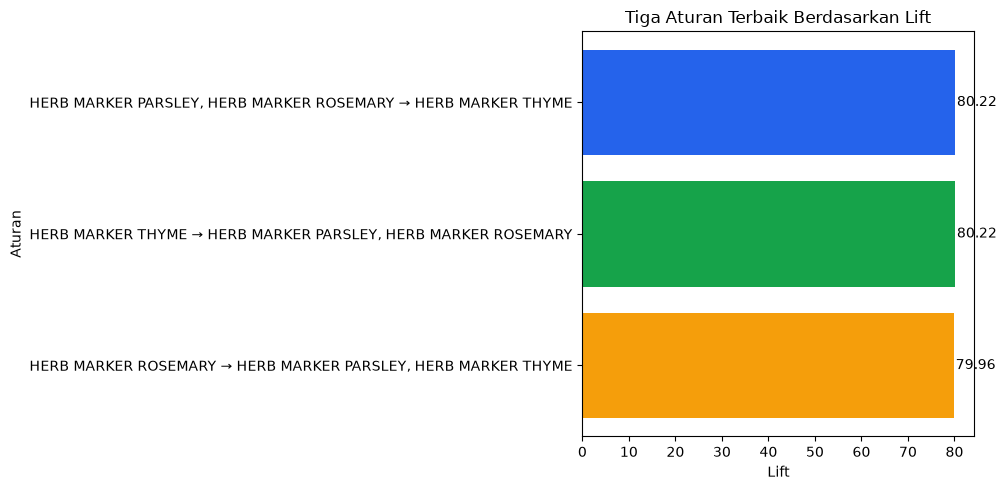

In [35]:
top_3_plot = top_3_rules.copy()

top_3_plot["aturan"] = (
    top_3_plot["antecedents_text"]
    + " → "
    + top_3_plot["consequents_text"]
)

plt.figure(figsize=(10, 5))

bars = plt.barh(
    top_3_plot["aturan"],
    top_3_plot["lift"],
    color=["#2563EB", "#16A34A", "#F59E0B"]
)

plt.gca().invert_yaxis()
plt.xlabel("Lift")
plt.ylabel("Aturan")
plt.title("Tiga Aturan Terbaik Berdasarkan Lift")

for bar, value in zip(bars, top_3_plot["lift"]):
    plt.text(
        value + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "top_3_association_rules.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()